# E94: Do readings inside the Qwen decomposition tell the template fine-tune from the TOFU facts fine-tune, and which does a known-facts fine-tune read like?

*2026-11-06 · `qwen-decomp-lead` · provisional, no independent check · report `reports/analyses/2026-11-06_analysis_e94-d3-rows.md`*

## The answer

Three readings separate the template fine-tune from the fictional-facts fine-tune: the share of the update outside the subcomponents, the share of the split on subcomponents already on, and the overlap with think mode's subcomponents. A third fine-tune, built like the fictional one but on facts the model already knows, reads on the fictional side. So these readings see the training task and format, not whether the content is new. At the end, placement gave no call.


## What we were trying to test

The third deliverable asks for readings that tell apart two known kinds of update: one that brings out an existing behaviour, and one that teaches content the model lacked. Its two example fine-tunes of Qwen3-1.7B, the anchors, are:

- **the template fine-tune**: 100 steps teaching a fixed answer layout, seeds 0 and 1, weight norm 0.49;
- **the TOFU facts fine-tune**: facts about fictional authors, seeds 42 and 142, read at three points. At the step matched to the template in norm, steps 29 and 30, it has **not** learned the facts: recall 0.157 and 0.173 against the untrained model's 0.179. At the first step past the learning line its norm is about 15. At its full update, step 1250, its norm is 18.1, **37 times** the template's.

A third fine-tune, the amendment's, asks what those readings follow:

- **the known-facts fine-tune**: the TOFU task, answer format and recipe, but on 217 real facts the model already knows, each answered in one sentence. Seeds 42 and 142. At step 32 its norm is 0.48, matched to both anchors; at its five-epoch end, step 335, it is 8.4, under half of TOFU's full update. If the readings follow the label "already known", it reads like the template; if they follow task and format, like TOFU.

Every TOFU reading at the full or past-line state carries a caveat. It may read a pull towards the training's names rather than only new content. On author questions, the share of answers stating a fact fell from 0.695 to 0.411 and 0.379. Accuracy on the whole set fell 7.4 and 11.1 points.

Each update is split by **least squares**: the least-norm change $(dU, dV)$ of the subcomponents' write and read vectors with $dU V^\top + U dV^\top \approx \delta W$. What the subcomponents cannot take stays in the leftover $\Delta$. **Do-nothing**, the reference, leaves the whole update in $\Delta$. Two **random changes** stand beside the anchors at two sizes, matched in output size to the template and to TOFU's full update. One is Gaussian; the other moves only the alive subcomponents. Output size is the KL from the untrained model on 128 maths rows, in nats per position; the table below gives it for every state.

The five readings:

1. **Direct share**: of what the split closes towards the fine-tuned model, the part the moved vectors close while each subcomponent's mask is held where the original model put it. 0 means they carry nothing by themselves; do-nothing reads 0.
2. **Outside share**: the share of the update's input-weighted energy outside the subcomponents, against its exact null. The null is a random update with the same per-matrix sizes.
3. **Placement excess**: of the split's energy, the share on subcomponents already switched on in the original model, minus the same share for Gaussian changes. 0 means no preference.
4. **Credit under masks**: behaviour kept under the state's own masks, as a share of the fine-tune's gain, by the split minus by do-nothing.
5. **Think overlap**: how far the subcomponents a state switches on overlap think mode's switched-on set, as a fold over chance. Beside it, the same fold for a no-think set matched in answer length. If the no-think set overlaps as much, the reading is not about thinking.

A reading **counts** when the two anchors' seed means differ by more than either anchor's own seed spread. At the full update we also ask whether the same rule counts between the two random sizes. If it does, size alone could make the gap.

For the known-facts fine-tune, its seed mean is placed on the line from the template's mean, at 0, to TOFU's, at 1. It reads **like TOFU** past 0.5 plus a noise margin, **like the template** below 0.5 minus it, and otherwise gives no call. The margin is the largest seed spread of the three arms, over the anchors' gap. Only at matched size do all three share a size, so that comparison decides; the end is description.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_d3_rows")
T = json.loads((ROOT / "results" / "table.json").read_text())
N = T["numbers"]
rows = [("template", "a1_s0", "a1_s1", "0.49, 0.49"), ("TOFU matched", "a2_s42_matched", "a2_s142_matched", "0.48, 0.50"),
        ("TOFU full", "a2_s42_full", "a2_s142_full", "18.1, 18.1"), ("TOFU past line", "a2_s42_past", "a2_s142_past", "15.5, 14.7"),
        ("random, small", "gauss_small", "alive_small", "Gaussian, alive"), ("random, big", "gauss_big", "alive_big", "Gaussian, alive")]
size = lambda s: f"{N[s]['printed']['size_K00_minus_K0']:.2f}"
lines = ["| state | output size, nats per position | weight norm, or kind |", "|---|---|---|"]
lines += [f"| {name} | {size(a)}, {size(b)} | {norm} |" for name, a, b, norm in rows]
display(Markdown("\n".join(lines)))


| state | output size, nats per position | weight norm, or kind |
|---|---|---|
| template | 0.13, 0.13 | 0.49, 0.49 |
| TOFU matched | 0.22, 0.23 | 0.48, 0.50 |
| TOFU full | 0.61, 0.66 | 18.1, 18.1 |
| TOFU past line | 0.64, 0.66 | 15.5, 14.7 |
| random, small | 0.14, 0.12 | Gaussian, alive |
| random, big | 0.53, 0.62 | Gaussian, alive |

## What we expected, and why

We filed our leans before the run. The direct share would be tiny everywhere, as in earlier reads. The template would sit at its random, and TOFU below its random at both sizes. Every update would sit inside the subcomponents more than its null. **Placement would not separate the anchors**, because two TOFU seeds had differed by 0.033 in an earlier run, as much as the states did. The template's credit would be under 0.01. Think mode and the no-think set would overlap alike, within 0.17 fold, as an earlier read found, with every fold between 3 and 4.

For the known-facts fine-tune, filed before its run: at matched size it would read like TOFU on outside share and placement, since it shares TOFU's rows type, format and recipe, and both sit about 30 steps into the same warm-up. Think overlap could not be called at matched size, as the anchors do not separate there. The end readings were filed as reported only.


### Does one fine-tune leave more of its update outside the subcomponents?


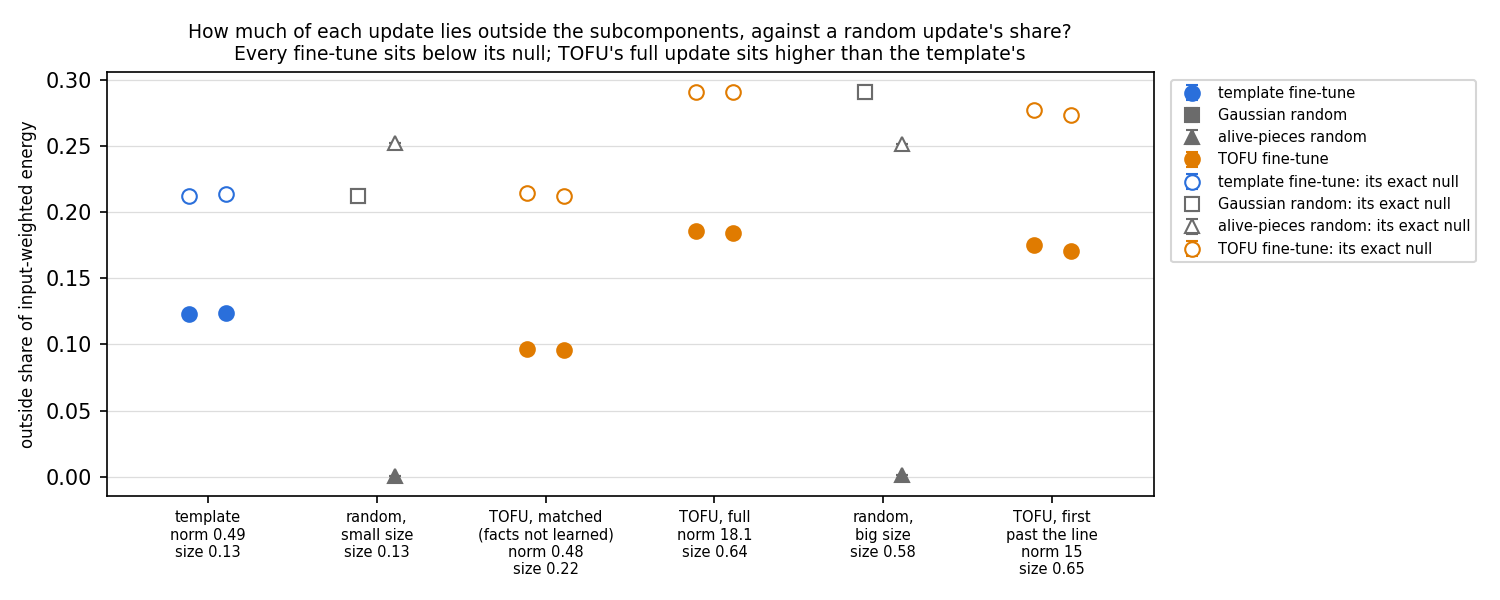

In [2]:
display(Image(ROOT / "figures" / "outside.png", width=850))


**Reading it.** Yes: TOFU's full update leaves more outside than the template, and every fine-tune leaves less than its null. Filled points are the updates, hollow points their exact nulls. The template leaves 0.12 of its input-weighted energy outside, TOFU's full update 0.18 to 0.19. Seeds agree within 0.005, so the gap counts. The two random sizes do not separate, but that check is weak: the two random kinds differ by 0.21 to 0.29. The share is a ratio, so scaling an update does not change it. The nulls differ, 0.21 for the template and 0.29 for TOFU's full update, so part of the gap is which matrices each update sits in. Against its null, the template reads 0.58 and TOFU's full update 0.64.


### Does the split favour subcomponents that were already on?


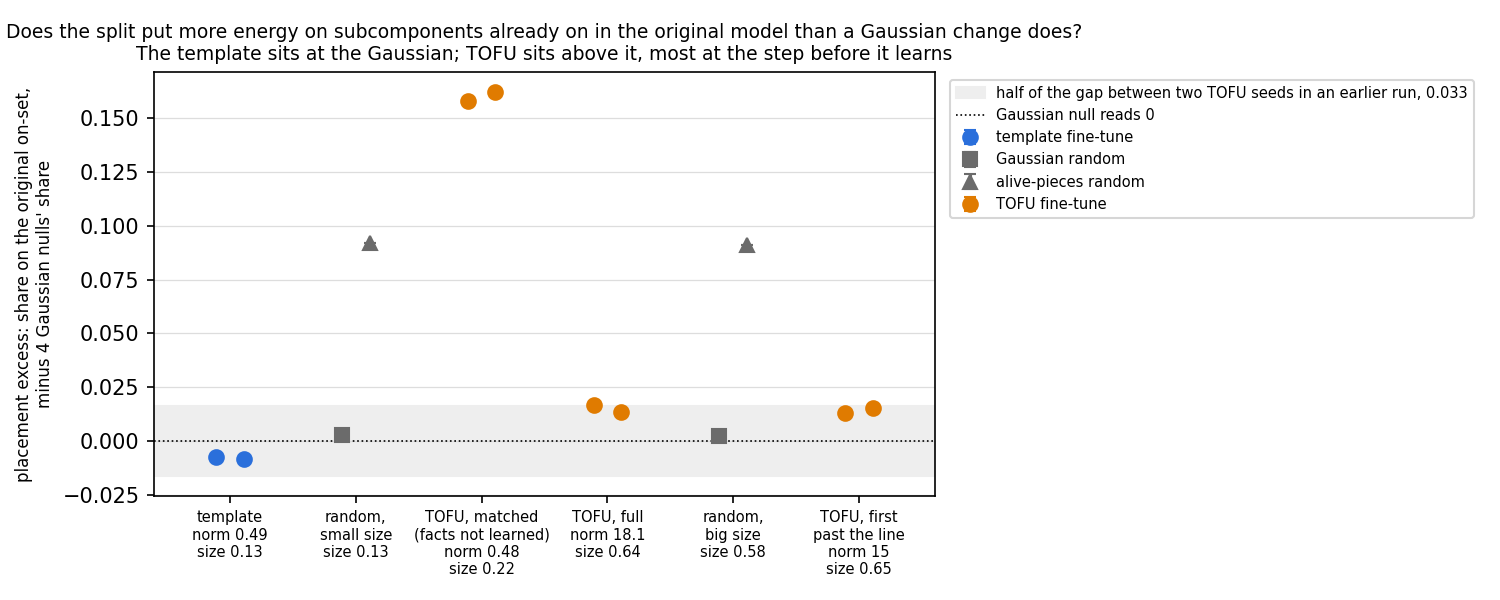

In [3]:
display(Image(ROOT / "figures" / "placement.png", width=850))


**Reading it.** For TOFU yes, for the template no, and this reverses our filed lean. The template sits at the Gaussian's level, -0.008 at both seeds. TOFU's full update reads 0.014 to 0.017, and its matched step, before it learns, 0.16. That is above even the change made only of alive subcomponents, at 0.09. Seeds differ by under 0.005, far less than the 0.033 we had borrowed. The random sizes do not separate, again with little power. This row's positive control sat at its line in an earlier run, so it is a weak row.


### Do the moved subcomponents carry more of one update by themselves?


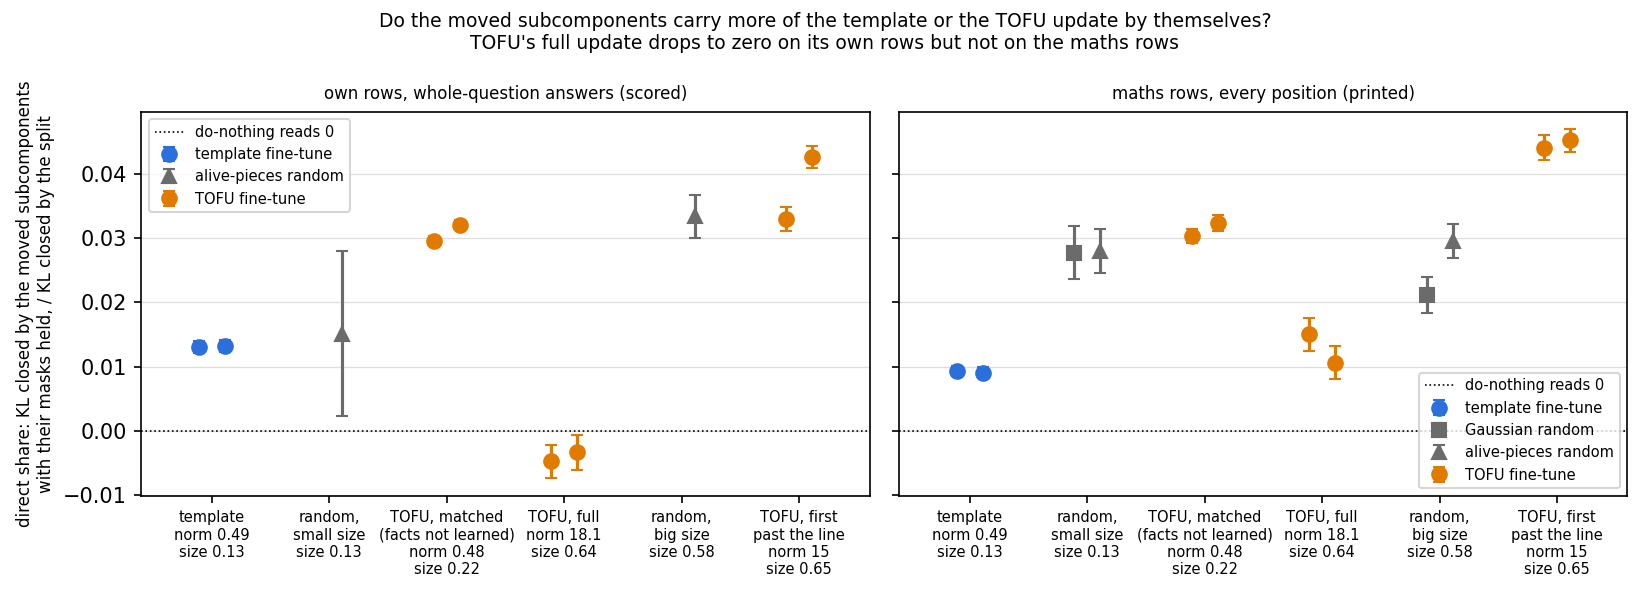

In [4]:
display(Image(ROOT / "figures" / "direct.png", width=1000))


**Reading it.** It depends on which rows are read, so this row is not carried. On each anchor's own question rows, the template reads 0.013 and TOFU's full update -0.005 and -0.003. TOFU's moved vectors carry nothing measurable by themselves there, below the random at its size, 0.033, as we filed. On the shared maths rows the same TOFU states read 0.015 and 0.011, against the template's 0.009, inside TOFU's seed spread. At the matched step TOFU reads 0.03 on both row sets, above the small random, not below as filed. Every value is under 0.05 of what the split closes.


### Does the split keep more behaviour under the masks than doing nothing?


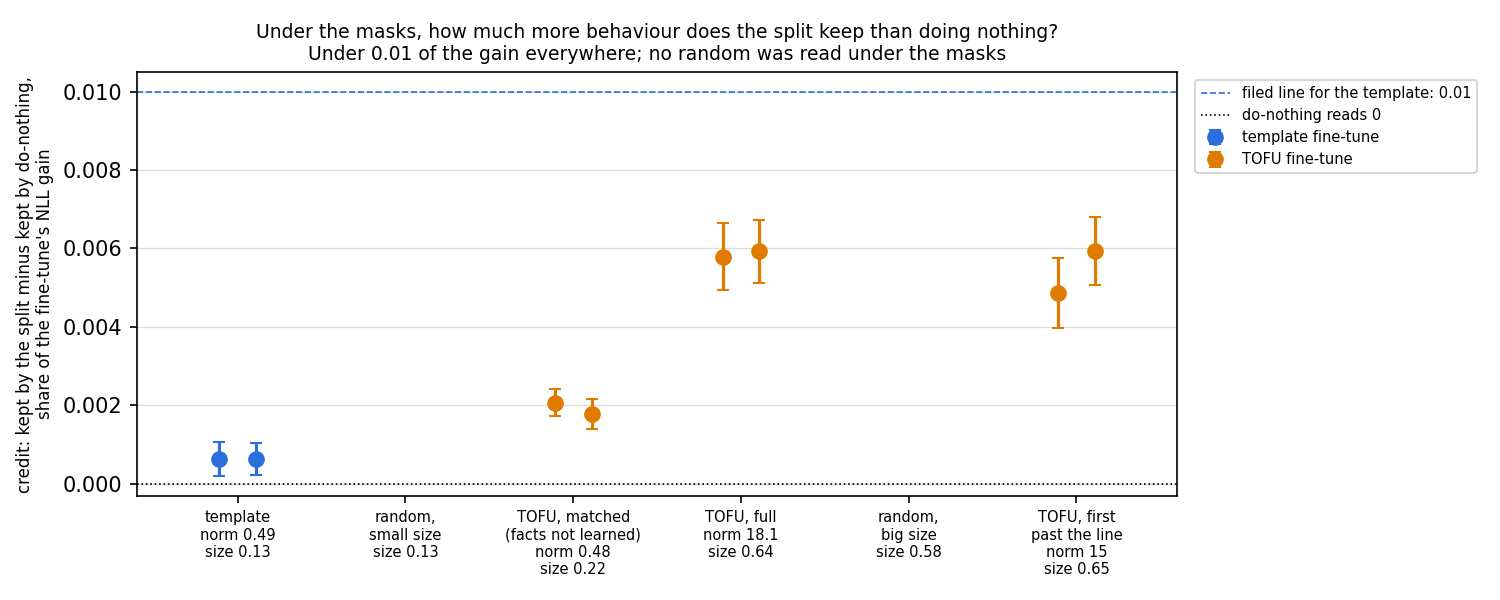

In [5]:
display(Image(ROOT / "figures" / "credit.png", width=850))


**Reading it.** Barely, and more for TOFU, but we cannot say whether size does that. The template's split keeps 0.0006 more of the gain than doing nothing, under the filed 0.01. TOFU's keeps 0.002 at the matched step and 0.006 at the full update, half-widths under 0.001, so the gap counts. No random change was read under the masks, so the size check is missing. Over every position rather than whole-question answers, TOFU's full update reads 0.001 and -0.005.


### Do the switched-on subcomponents overlap think mode's?


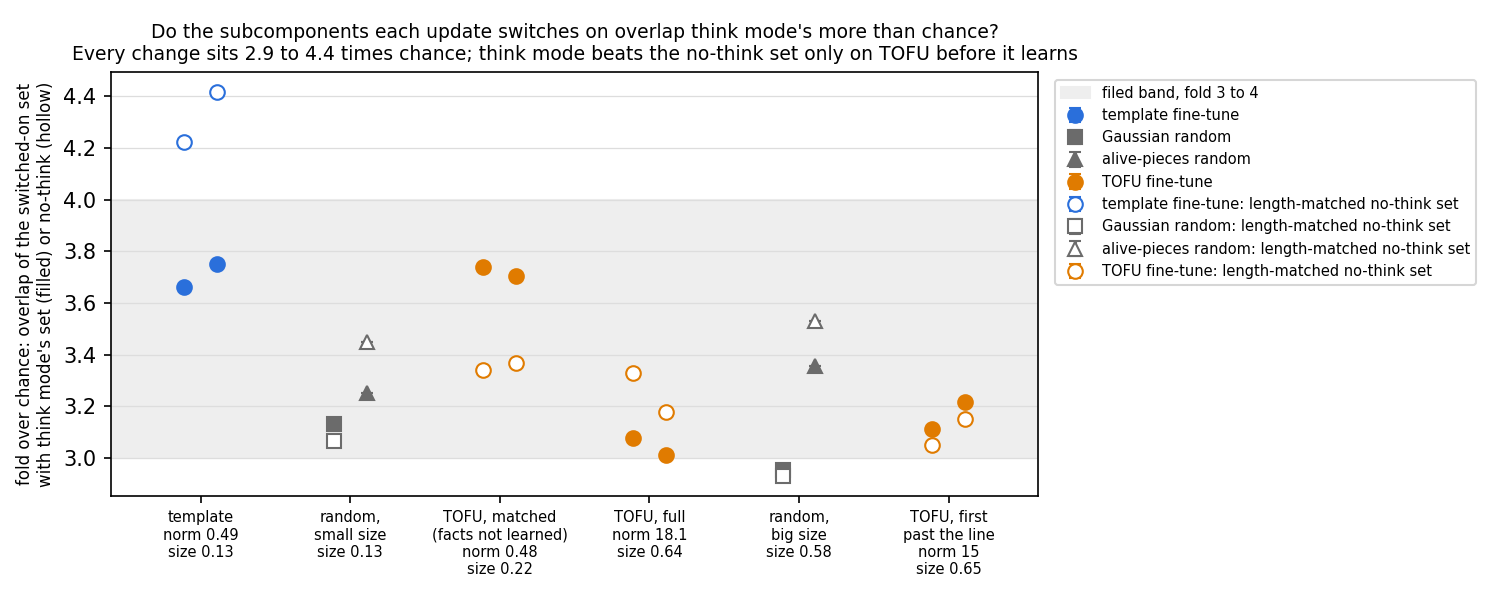

In [6]:
display(Image(ROOT / "figures" / "think.png", width=850))


**Reading it.** Every change overlaps think mode's set 2.9 to 4.4 times chance, random ones included, and the reading is not about thinking. The template overlaps the no-think set more than think mode's: 4.2 and 4.4 against 3.7 and 3.8. Only TOFU's matched step overlaps think mode more, by 0.3 to 0.4. At the full update the anchors separate, the template's 3.7 against TOFU's 3.0, and the random sizes do not. TOFU's full update sits between the two big randoms; the template sits above both small ones. Both filed think leans missed.


### Does a fine-tune on facts the model already knows read like the template or like TOFU?


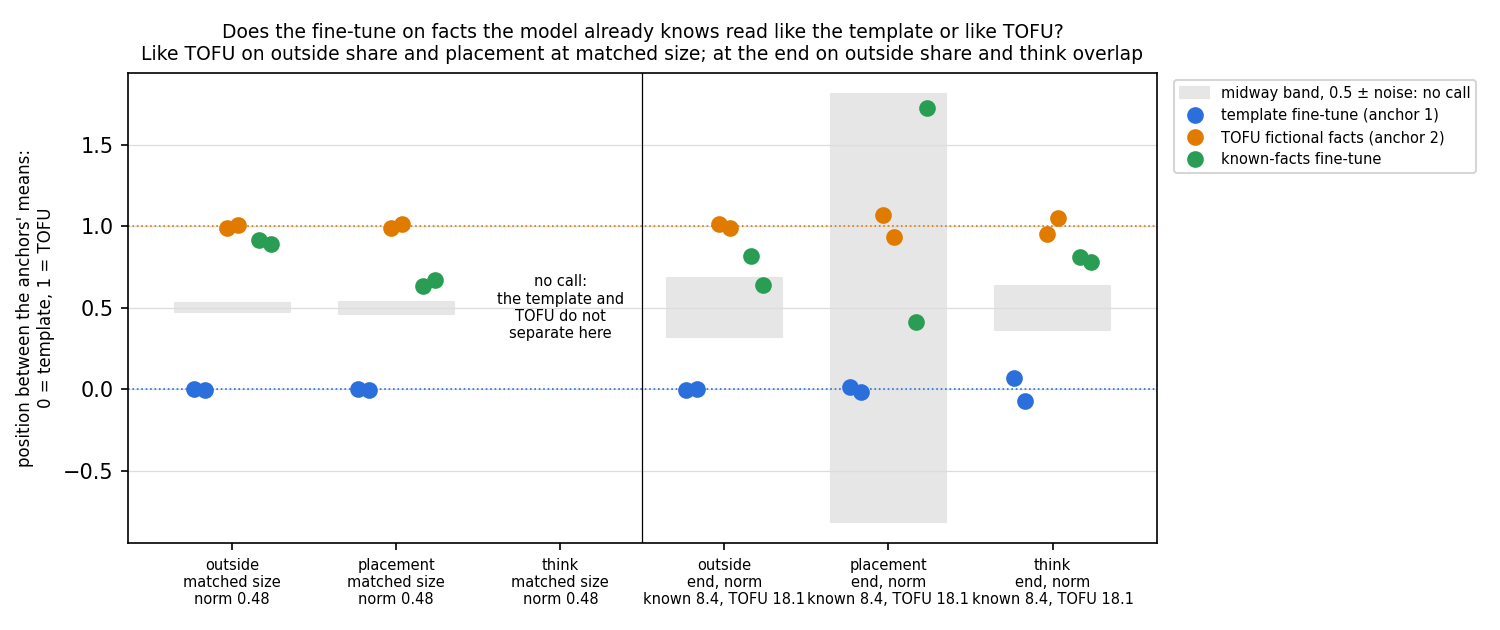

In [7]:
display(Image(ROOT / "figures" / "known.png", width=950))


**Reading it.** Like TOFU: at matched size the known-facts fine-tune sits on TOFU's side on both readings that decide, so these readings do not follow the label "already known". Each dot is one seed, placed between the template's mean at 0 and TOFU's at 1; the grey band is where the rule gives no call. On outside share it sits nine-tenths of the way to TOFU, and on placement about two-thirds, just past the band. On both it still differs from TOFU by more than the seeds do, so it is near TOFU, not the same.

At the end, set beside TOFU's full update, outside share and think overlap also read like TOFU. Placement gives no call there: its two seeds disagree by more than the anchors' whole gap. One caveat: divided by its own null, the end's outside share sits one-third of the way to TOFU, on the template's side, so that verdict depends on the form. The matched outside verdict holds in both forms.

| reading, size | known-facts, two seeds | template | TOFU | verdict |
|---|---|---|---|---|
| outside, matched | 0.099; 0.099 | 0.123; 0.124 | 0.096; 0.096 | like TOFU |
| placement, matched | 0.099; 0.105 | -0.008; -0.008 | 0.158; 0.162 | like TOFU |
| think, matched | 3.65; 3.59 | 3.66; 3.75 | 3.74; 3.71 | no call |
| outside, end | 0.174; 0.163 | as above | 0.186; 0.184 | like TOFU |
| placement, end | 0.002; 0.032 | as above | 0.017; 0.014 | no call |
| think, end | 3.17; 3.19 | as above | 3.08; 3.01 | like TOFU |

TOFU at the end is its full update, at 2.2 times the known-facts end's norm. The known-facts output size is 0.15 at matched size and 0.36 to 0.41 at the end.


## What each reading means for the next step

No control failed and some readings count, so the plan's stop rule does not apply. At the matched step TOFU has not learned its facts. A count there reads the opening steps of a fine-tune against a finished one, not content the update recalls.

| reading | matched step | full update | size can do it | to the maths arms |
|---|---|---|---|---|
| direct share | counts | own rows only | not read on own rows | printed, not carried |
| outside share | counts | counts | no, weak check | **carried** |
| placement excess | counts | counts | no, weak check | **carried**, weak row |
| credit under masks | counts | counts | not read | printed |
| think overlap | does not count | counts | no | **carried**, as overlap, not thinking |

The three carried readings were read on the maths arms in E104: reinforcement learning, its shuffled-reward null and the own-samples fine-tune. The known-facts fine-tune lands on the plan's first branch: both deciding readings read like TOFU at matched size. So the carried readings are descriptions of the training's task and format, not of new against known content, and D3's write-up says the decomposition's readings do not see "already known" on this pair. No end reading goes against the matched verdict.


## What we learned

The decomposition sees the template and TOFU fine-tunes differently on three readings that our random changes do not reproduce by size. TOFU's full update sits partly in matrices with a larger outside null, and its opening steps put far more of the split on already-on subcomponents than its finished update does.

The known-facts fine-tune says what those readings follow. Built like TOFU but on facts the model already knows, it reads on TOFU's side, so they follow the training's task and format, not whether the content is new. For the goal's question of new capability against strengthening, these readings cannot by themselves tell the two apart on this pair. One limit stands for any such claim: a new circuit assembled from subcomponents the model already has reads as brought out, not taught, to the decomposition.


## How compelling is the evidence

- Two seeds per anchor. Seed spreads are tiny, under 0.005 on outside and placement, so "counts" is easy to meet and says nothing about whether a gap matters.
- One random draw per kind and size. The size check pairs the two kinds, whose values differ far more than size moves them on outside and placement.
- Outside share and think overlap describe the update and its masks, not the split; do-nothing reads the same.
- Placement's positive control sat at its line in an earlier run.
- Direct share and credit are under 0.05 of what they divide, and on TOFU's full update they move with the choice of positions.
- Two anchors, one Qwen model, one decomposition.
- The known-facts fine-tune has two seeds. Reading like TOFU cannot tell task, format and the recipe's warm-up phase apart. At matched size TOFU has not yet learned its facts, so the deciding comparison sets two opening phases side by side, both gaining on their trained answers. Placement there is only just past the band. The end compares states 2.2 times apart in norm, and its outside verdict changes side when divided by the null.


## Surprises

**Something unexpected happened that I cannot explain.** We filed that placement would not separate the anchors; it separates them at both sizes. TOFU's step before it learns puts 0.16 more of its split on already-on subcomponents than a Gaussian change. That is more than a change built only from alive subcomponents. Smaller: TOFU's matched direct share sits above the random, not below; the template overlaps the no-think set more than think mode.

For the known-facts fine-tune, none: every filed lean held. Its end seeds disagree on placement by more than the anchors' gap.


## What next

- An anchor 2 state saved near the known-facts end's norm of 8.4 would make the end a size-matched comparison. If the known-facts end then sits on the template's side, the end verdicts were size, not task.
- Read one random change under the masks at each size. If it reaches TOFU's credit of 0.006, credit is size.
- A second random draw per kind would give the size check its own spread.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| 1_a1 | template's direct share at the small random | within 0.01, both seeds | 0.013, 0.013 against 0.015 | holds |
| 1_a2 | TOFU matched below the small random | below, both seeds | 0.030, 0.032 against 0.017 | misses |
| 2 | TOFU full below the big random | below, both seeds | -0.005, -0.003 against 0.033 | holds |
| 3 | every state under its outside null by more than its seed spread | margin over spread | smallest margin 0.089 | holds |
| 4 | placement does not count at either size | comparison rule | counts at both | **misses, reversed** |
| 5 | template's credit under 0.01 | both seeds | 0.0006, 0.0006 | holds |
| 6_T_like_L | think and no-think within 0.17 everywhere | all 8 states | template -0.56, -0.67 | misses |
| 6_fold_3_to_4 | every fold 3 to 4 | all states and randoms | template no-think 4.4; big Gaussian 2.9 | misses |
| K1 | known-facts outside share at matched size like TOFU | position over 0.5 plus noise | 0.90, noise 0.027 | holds |
| K2 | known-facts placement at matched size like TOFU | as K1 | 0.65, noise 0.035 | holds |
| K3 | known-facts think overlap at matched size: no call | anchors do not separate | they do not | holds |
| K4 | known-facts outside share at the end | reported | 0.73, noise 0.18: like TOFU | reported |
| K5 | known-facts placement at the end | reported | 1.07, noise 1.31: no call | reported |
| K6 | known-facts think overlap at the end | reported | 0.79, noise 0.14: like TOFU | reported |

Every control of the known-facts jobs passed; the original model run as the fine-tuned one on the new rows matched to a relative 2.8e-16.


## Departures from the literature

- In VPD, Γ reads the current model through the current read vectors. The direct share and think overlap read masks through the original read vectors inside the moved state, so that masks are held while vectors move. Credit uses the state's own vectors, as VPD does.
- "Switched on" is an importance value over 0.01 at 1% or more of positions; VPD has continuous values and no on-set.
- TOFU is Maini et al.'s fictional-author set, fine-tuned with this project's own recipe, not the paper's.
- Think and no-think sets are this project's, built from the original model's answers with Qwen3's thinking switch.
- Outside share, placement excess, credit and fold are this project's measurements.


## Not run

The adversary. Teacher training. A random change under the masks. An own-row size check for the direct share. More than one random draw per kind and size. The ceiling under masks. TOFU states at steps 100 and 200. Think sets built on TOFU's own questions. An independent check. For the known-facts fine-tune: a TOFU state at norm 8.4; a random change at its end's output size; a third seed; E107's wrong-answer states, not read; the neuron readings, which are baseline-lead's.

**Provenance.** Seven `debug` jobs on one L40 each, $0, about 5.2 h of card: 52779 control, 52825, 52941, 53031, 53072, 53102, 53130. The known-facts fine-tune: jobs 53491 and 53641, 55 min each, $0; states are baseline-lead's E103 Amendments 1 and 2. Results in `experiments/qwen_d3_rows/results/`, the amendment's in `table_amend1.json`; full tables in the report.
